# Assignment 3.1: Support vector machines

The support vector machine comes from scikit-learn's `SVC` class. You do not implement it. Your job
is to configure it with the right kernel and regularization for each run, train and test the models,
and write the report from the boundary plots and the accuracy table.

Two code cells are yours: `fit_svm` and `run_experiments`. Everything else, including the
`accuracy` function, is provided and already runs.

# Import libraries
Do not use any other Python library.

numpy - Linear algebra library for handling vectors and matrices, collectively processed as numpy arrays.

matplotlib - Graphing library for visualizing results.

sklearn - Machine learning library from which we source the train and test split and the support vector machine classifier.

time - Simple library for timing code.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from time import time

# Load Datasets

These functions load the four datasets. Each one has two input features and a binary target.

`load_folder` reads a dataset that comes already split into training and test files: Linear
Separable, Breast Cancer Wisconsin, and Ellipse. The Breast Cancer features are worst area and worst
smoothness, both standardized, and the target is 1 for a malignant tumor and 0 for a benign one.

`load_spirals` reads the Spirals dataset from one file and splits it here. 20% of the points go to
the test set. The split is stratified and seeded, so every run gets the same split.

Outputs:

*   **X_train**, **y_train**: training features, shape (N, 2), and integer labels
*   **X_test**, **y_test**: test features and integer labels

# Function: show_datasets

Draws the training points of every dataset side by side.

Input:
*   **datasets**: dictionary mapping each dataset name to its (X_train, y_train, X_test, y_test)

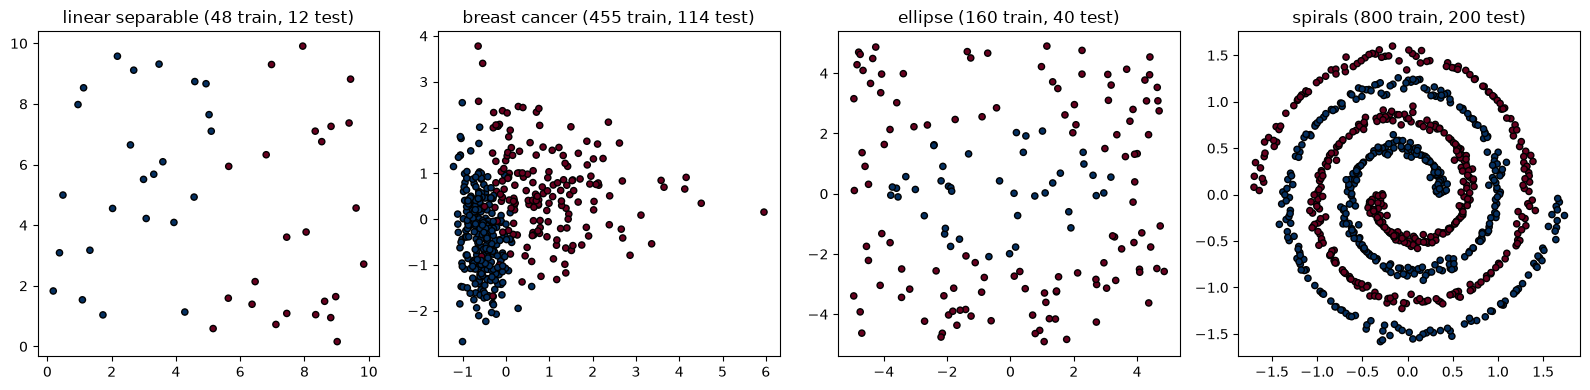

In [2]:
def load_folder(folder):
    # these files have no header row
    X_train = np.loadtxt(f'../data/{folder}/train_inputs.csv', delimiter=',')
    y_train = np.loadtxt(f'../data/{folder}/train_targets.csv', delimiter=',').astype(int)
    X_test = np.loadtxt(f'../data/{folder}/test_inputs.csv', delimiter=',')
    y_test = np.loadtxt(f'../data/{folder}/test_targets.csv', delimiter=',').astype(int)
    return X_train, y_train, X_test, y_test


def load_spirals():
    # header is ",x,y,class" and the first column is a row index
    data = np.loadtxt('../data/spirals.csv', delimiter=',', skiprows=1)
    features = data[:, 1:3]
    labels = data[:, 3].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        features, labels, test_size=0.2, random_state=0, stratify=labels)
    return X_train, y_train, X_test, y_test


def show_datasets(datasets):
    figure, axes = plt.subplots(1, len(datasets), figsize=(4 * len(datasets), 4))
    for axis, (name, (X_train, y_train, X_test, y_test)) in zip(axes, datasets.items()):
        axis.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.RdBu_r,
                     edgecolors='k', s=20)
        axis.set_title(f'{name} ({len(y_train)} train, {len(y_test)} test)')
    plt.tight_layout()
    plt.show()


datasets = {
    "linear separable": load_folder('linear_separable'),
    "breast cancer": load_folder('breast_cancer'),
    "ellipse": load_folder('ellipse'),
    "spirals": load_spirals(),
}
show_datasets(datasets)

# Experiment plan

The runs the spec asks for. Linear Separable gets the linear kernel at C = 1.0. The other three
datasets each get the degree 2 polynomial kernel and the radial basis function kernel, each at
C = 1.0 and C = 1000.0. That is 13 models in all. The kernel names are the ones `SVC` uses.

In [3]:
EXPERIMENTS = {
    "linear separable": {"kernels": ["linear"], "C_values": [1.0]},
    "breast cancer": {"kernels": ["poly", "rbf"], "C_values": [1.0, 1000.0]},
    "ellipse": {"kernels": ["poly", "rbf"], "C_values": [1.0, 1000.0]},
    "spirals": {"kernels": ["poly", "rbf"], "C_values": [1.0, 1000.0]},
}
POLY_DEGREE = 2

# Function: fit_svm

Builds one `SVC` with the given kernel and regularization value C and trains it on the training set.
The polynomial kernel uses degree `POLY_DEGREE`. Leave every other argument at its library default.
Look up the `SVC` constructor to find which arguments choose the kernel, set C, and set the
polynomial degree.

Inputs:
*   **X_train**, **y_train**: training features and labels
*   **kernel**: "linear", "poly", or "rbf" (string)
*   **C**: regularization value (float). A larger C penalizes margin violations more, so it regularizes less.

Output:
*   **model**: the fitted `SVC`

In [ ]:
def fit_svm(X_train, y_train, kernel, C):
    # 1. build the classifier with the given kernel and C, and the polynomial degree when the kernel is polynomial
    if kernel == "poly":
        svm_model = SVC(
            C=C,
            kernel=kernel,
            degree=POLY_DEGREE
        )
    else:
        svm_model = SVC(
            C=C,
            kernel=kernel
        )
    # 2. train it on the training set and return it
    svm_model.n
    return svm_model.fit(X_train, y_train)

# Function: accuracy

This function is provided. It returns the percentage of instances whose predicted label matches the
true label.

Inputs:
*   **model**: a fitted classifier
*   **X**: features, shape (N, 2)
*   **y**: true labels

Output:
*   **accuracy**: percentage of correct predictions (float)

In [6]:
def accuracy(model, X, y):
    return float(np.mean(model.predict(X) == y)) * 100

# Function: run_experiments

Runs every model in `EXPERIMENTS`: for each dataset, each of its kernels, and each of its C values,
train a model on that dataset's training set with your `fit_svm` and score it on both the training
set and the test set with the provided `accuracy`. Also record how many support vectors the fitted model kept, over both classes.

The cells below print and plot whatever this function returns, so the dictionary has to have
exactly this shape. Its keys are (dataset name, kernel, C) tuples, and each value is a dictionary
with these four keys:

*   **model**: the fitted `SVC`
*   **train_accuracy**: accuracy on the training set (float)
*   **test_accuracy**: accuracy on the test set (float)
*   **support_vectors**: number of support vectors (integer)

Input:
*   **datasets**: dictionary mapping each dataset name to its (X_train, y_train, X_test, y_test)

Output:
*   **results**: the dictionary described above

In [37]:
def run_experiments(datasets):
    results = {}
    # 1. loop over the datasets in the plan, and over each kernel and C value listed for that dataset
    for dataset in datasets.keys(): # to make sure the dataset and experiment is matched
        X_train, y_train, X_test, y_test = datasets[dataset]
        experiment = EXPERIMENTS[dataset]
        for kernel in experiment["kernels"]:
            for c in experiment["C_values"]:
    # 2. fit a model on that dataset's training set
                model = fit_svm(X_train, y_train, kernel, c)
    # 3. score it on the training set and on the test set
                score_train = accuracy(model, X_train, y_train)
                score_test = accuracy(model, X_test, y_test)
    # 4. count its support vectors over both classes
                n_svs = model.n_support_
    # 5. store the four values under the (dataset, kernel, C) key
                results[(dataset, kernel, c)] = {
                    "model": model,
                    "train_accuracy": score_train,
                    "test_accuracy": score_test,
                    "support_vectors": n_svs.sum()
                }
    return results

# Function: plot_boundary

Draws one fitted model on one axis. The shaded regions are the two predicted classes. The solid line
is the decision boundary, where the decision function is 0, and the dashed lines are the margins,
where it is -1 and +1. Training points are filled, test points are hollow, and the support vectors
are circled in black. The title gives the number of support vectors and the test accuracy.

Inputs:
*   **model**: a fitted `SVC`
*   **X_train**, **y_train**: training features and labels
*   **X_test**, **y_test**: test features and labels
*   **title**: title for the axis (string)
*   **ax**: the matplotlib axis to draw on

# Function: plot_dataset

Draws every model of one dataset: one panel for Linear Separable, and a 2 by 2 grid for the other
datasets, with one row per kernel and one column per C value.

Inputs:
*   **dataset_name**: name of the dataset (string)
*   **results**: the dictionary returned by `run_experiments`

In [38]:
def plot_boundary(model, X_train, y_train, X_test, y_test, title, ax):
    points = np.vstack([X_train, X_test])
    padding = 0.1 * (points.max(axis=0) - points.min(axis=0))
    low = points.min(axis=0) - padding
    high = points.max(axis=0) + padding
    grid_x, grid_y = np.meshgrid(np.linspace(low[0], high[0], 200),
                                 np.linspace(low[1], high[1], 200))
    grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    scores = model.decision_function(grid).reshape(grid_x.shape)

    # predicted class regions, then the boundary and the two margins
    ax.contourf(grid_x, grid_y, (scores > 0).astype(float), levels=[-0.5, 0.5, 1.5],
                colors=['#c6dbef', '#fcbba1'], alpha=0.8)
    ax.contour(grid_x, grid_y, scores, levels=[-1, 0, 1], colors='k',
               linestyles=['--', '-', '--'], linewidths=[1, 1.5, 1])

    colors = np.array(['#2166ac', '#b2182b'])
    ax.scatter(X_train[:, 0], X_train[:, 1], c=colors[y_train], s=18, label='train')
    ax.scatter(X_test[:, 0], X_test[:, 1], facecolors='none', edgecolors=colors[y_test],
               s=30, linewidths=1.2, label='test')
    support = model.support_vectors_
    ax.scatter(support[:, 0], support[:, 1], facecolors='none', edgecolors='k',
               s=70, linewidths=0.6, label='support vector')

    ax.set_xlim(low[0], high[0])
    ax.set_ylim(low[1], high[1])
    test_score = np.mean(model.predict(X_test) == y_test) * 100
    ax.set_title(f'{title}\n{len(support)} support vectors, test {test_score:.1f}%')


def plot_dataset(dataset_name, results):
    X_train, y_train, X_test, y_test = datasets[dataset_name]
    plan = EXPERIMENTS[dataset_name]
    rows, columns = len(plan["kernels"]), len(plan["C_values"])
    figure, axes = plt.subplots(rows, columns, figsize=(5.5 * columns, 5 * rows), squeeze=False)
    for row, kernel in enumerate(plan["kernels"]):
        for column, C in enumerate(plan["C_values"]):
            model = results[(dataset_name, kernel, C)]["model"]
            plot_boundary(model, X_train, y_train, X_test, y_test,
                          f'{dataset_name}, {kernel} kernel, C = {C:g}', axes[row, column])
    axes[0, 0].legend(loc='best', fontsize=8)
    plt.tight_layout()
    plt.show()

# Main SVM code

Runs all 13 models, then draws the boundary plots for each dataset. All of it takes a few seconds.

elapsed time: 0.3s


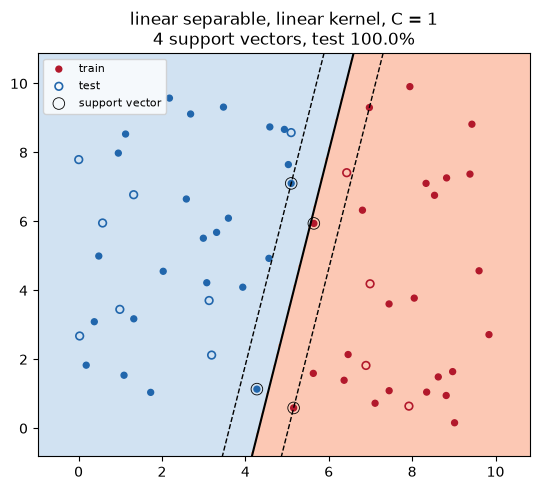

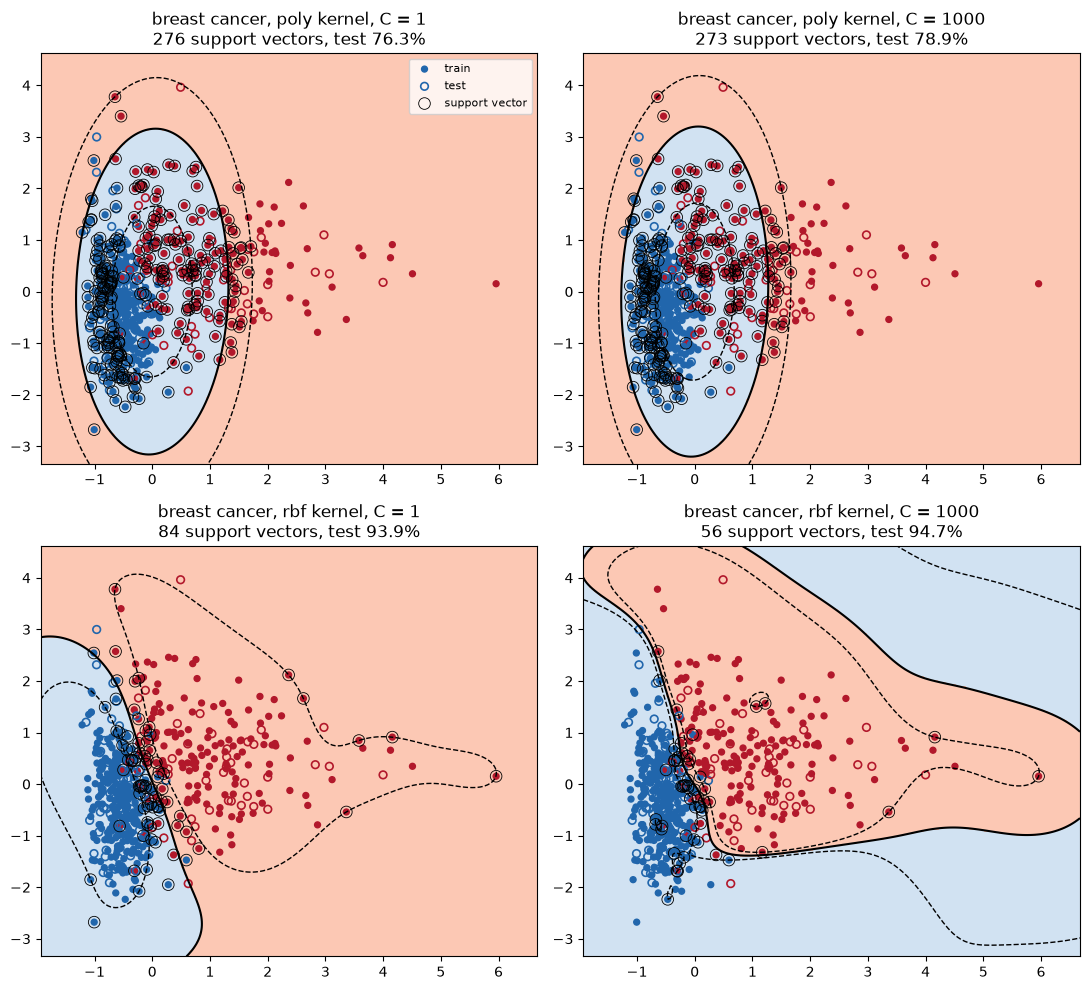

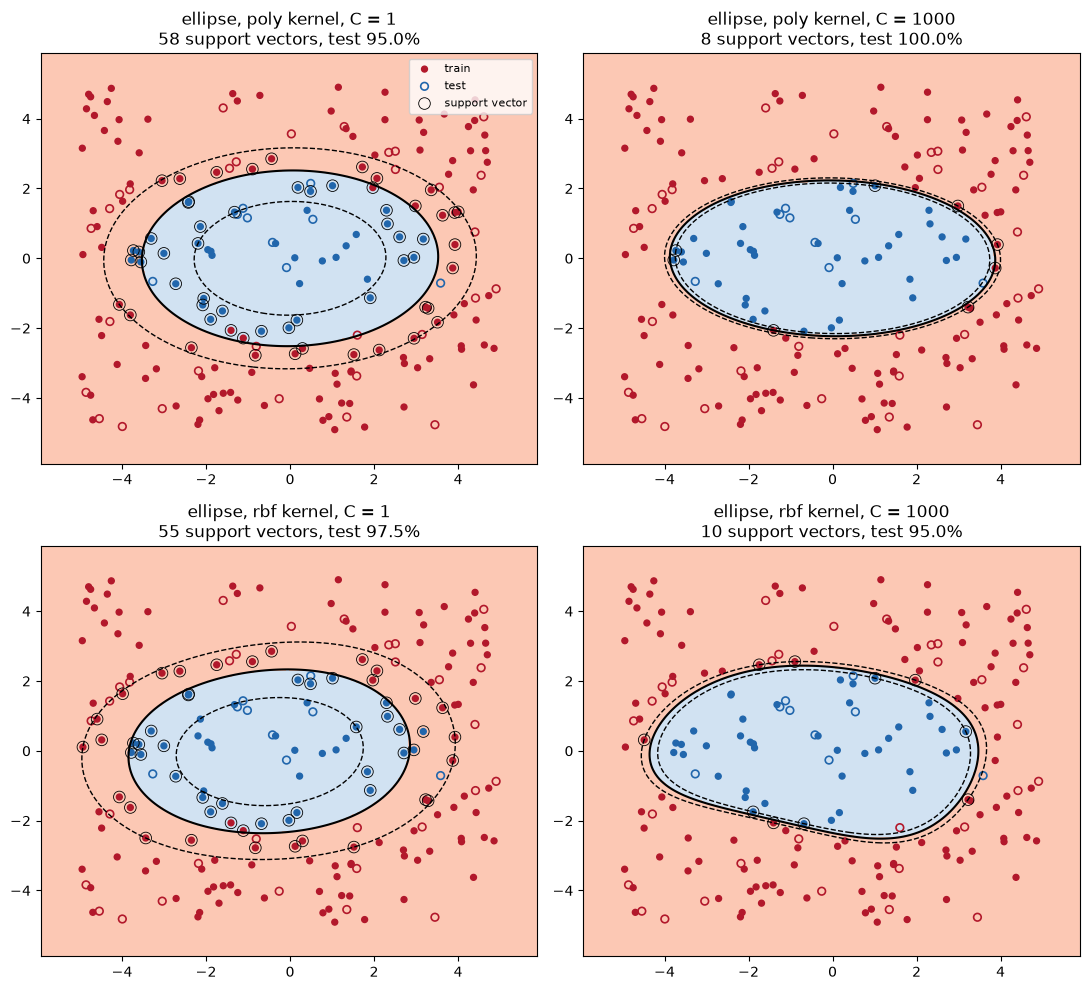

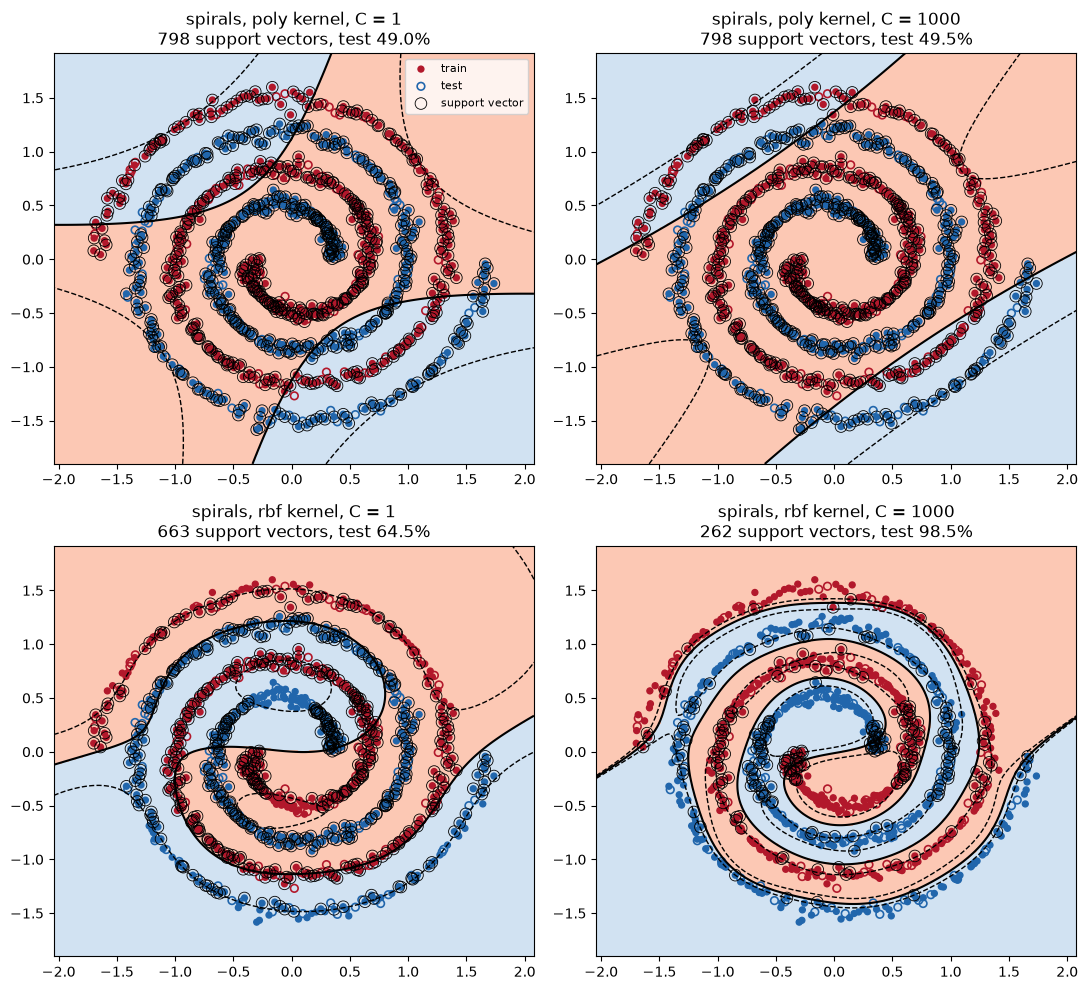

In [39]:
start_time = time()
results = run_experiments(datasets)
print(f"elapsed time: {time() - start_time:.1f}s")

for dataset_name in EXPERIMENTS:
    plot_dataset(dataset_name, results)

# Accuracy table

Training accuracy, test accuracy, and support vector count of all 13 models.

In [40]:
print(f"{'dataset':18s}{'kernel':8s}{'C':>8s}{'train':>10s}{'test':>10s}{'SVs':>7s}")
for (dataset_name, kernel, C), result in results.items():
    print(f"{dataset_name:18s}{kernel:8s}{C:8g}{result['train_accuracy']:9.2f}%"
          f"{result['test_accuracy']:9.2f}%{result['support_vectors']:7d}")

dataset           kernel         C     train      test    SVs
linear separable  linear         1   100.00%   100.00%      4
breast cancer     poly           1    74.07%    76.32%    276
breast cancer     poly        1000    74.73%    78.95%    273
breast cancer     rbf            1    96.04%    93.86%     84
breast cancer     rbf         1000    96.92%    94.74%     56
ellipse           poly           1    95.62%    95.00%     58
ellipse           poly        1000   100.00%   100.00%      8
ellipse           rbf            1    97.50%    97.50%     55
ellipse           rbf         1000   100.00%    95.00%     10
spirals           poly           1    50.38%    49.00%    798
spirals           poly        1000    50.00%    49.50%    798
spirals           rbf            1    66.88%    64.50%    663
spirals           rbf         1000    96.62%    98.50%    262


# Report

Cover the following for this notebook.

*   The decision boundary plot of every model.
*   A table of the training accuracy, test accuracy, and support vector count of all 13 models.
*   The effect of raising C from 1.0 to 1000.0 on each nonlinear dataset and kernel: how the boundary and the margins change, how the number of support vectors changes, and how training accuracy and test accuracy move relative to each other.
*   The polynomial kernel's boundary on Ellipse against its boundary on Breast Cancer. Explain why the same degree 2 kernel fits one dataset and not the other, in terms of what shapes a degree 2 boundary can take.
*   The polynomial kernel against the RBF kernel on Spirals, and why.
*   The kernel and C value you would choose for each dataset, and why.